# Exploratory Data Analysis for GoEmotions Dataset 1-3


### Import modules as required

In [2]:
# run(if you dont have all the modules): pip install -r requirements.txt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import norm #hi

### Loading, Combining and reading the dataset

run this in your terminal: brew install wget


wget -P data/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_1.csv

wget -P data/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_2.csv

wget -P data/ https://storage.googleapis.com/gresearch/goemotions/data/full_dataset/goemotions_3.csv


In [3]:
df1 = pd.read_csv('data/goemotions_1.csv')
df2 = pd.read_csv('data/goemotions_2.csv')
df3 = pd.read_csv('data/goemotions_3.csv')

In [4]:
df_large = pd.concat([df1,df2,df3], ignore_index=True)

In [5]:
df_large.shape

(211225, 37)

In [6]:
df_large.head()

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,1.548381e+09,1,False,0,...,0,0,0,0,0,0,0,1,0,0
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,1.548084e+09,37,True,0,...,0,0,0,0,0,0,0,0,0,0
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,1.546428e+09,37,False,0,...,0,0,0,0,0,0,0,0,0,1
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,1.547965e+09,18,False,0,...,1,0,0,0,0,0,0,0,0,0
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,1.546669e+09,2,False,0,...,0,0,0,0,0,0,0,0,0,1


In [7]:
df_large.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211225 entries, 0 to 211224
Data columns (total 37 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   text                  211225 non-null  object 
 1   id                    211225 non-null  object 
 2   author                211225 non-null  object 
 3   subreddit             211225 non-null  object 
 4   link_id               211225 non-null  object 
 5   parent_id             211225 non-null  object 
 6   created_utc           211225 non-null  float64
 7   rater_id              211225 non-null  int64  
 8   example_very_unclear  211225 non-null  bool   
 9   admiration            211225 non-null  int64  
 10  amusement             211225 non-null  int64  
 11  anger                 211225 non-null  int64  
 12  annoyance             211225 non-null  int64  
 13  approval              211225 non-null  int64  
 14  caring                211225 non-null  int64  
 15  

### data cleaning

In [8]:
# check for duplicated rows
df_large.duplicated().sum()

np.int64(0)

In [9]:
# check for duplicate columns
df_large.T.duplicated().sum()

np.int64(0)

In [10]:
# check if there are any repeated in BOTH text and subreddit
df_large.duplicated(subset=["text",'subreddit']).sum()

np.int64(153221)

In [11]:
# Remove duplicate, keep first occurrence
df_clean_duptexts_and_subreddits = df_large.drop_duplicates(subset=["text", 'subreddit'], keep="first")

print(f"Original shape: {df_large.shape}")
print(f"Clean shape:    {df_clean_duptexts_and_subreddits.shape}")
print(f"Removed: {df_large.shape[0] - df_clean_duptexts_and_subreddits.shape[0]} rows")

df = df_clean_duptexts_and_subreddits


Original shape: (211225, 37)
Clean shape:    (58004, 37)
Removed: 153221 rows


Why remove duplicate (text + subreddit) rows:

- Same text + same subreddit = data error (crosspost/data bug)

- Creates label inconsistency (different annotators)

- Biases model (overfits to repeated examples)

- Wastes compute/storage

- Same text in different subreddits = legit context variation (keep)

In [12]:
# Missing values per column
na = df.isna().sum().sort_values(ascending=False)
na[na > 0].head(20)

Series([], dtype: int64)

In [13]:
# Empty/whitespace-only text
empty_text = df["text"].astype(str).str.strip().eq("")
empty_text.sum()

np.int64(0)

## Text EDA

In [14]:
# Identify label columns (keep metadata separate)
meta_cols = ["text","id","author","subreddit","link_id","parent_id","created_utc","rater_id","example_very_unclear"]
label_cols = [c for c in df.columns if c not in meta_cols]

# Ensure labels are numeric 0/1
df[label_cols] = df[label_cols].apply(pd.to_numeric, errors="coerce")

# How many labels per row?
labels_per_row = df[label_cols].sum(axis=1)
labels_per_row.describe()

# returns (rows with no label, rows with more than 1 level)
(labels_per_row == 0).sum(), (labels_per_row > 1).sum()


/var/folders/sh/7m7czn5x4rj4rn1dlv0q20s80000gn/T/ipykernel_17596/3815013056.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[label_cols] = df[label_cols].apply(pd.to_numeric, errors="coerce")


(np.int64(847), np.int64(10165))

In [15]:
# class balance (how frequent is each emotion, top 10 emotions only)
label_counts = df[label_cols].sum().sort_values(ascending=False)
label_pct = (label_counts / len(df) * 100).round(2)
label_counts.head(10), label_pct.head(10)


(neutral        15523
 admiration      4860
 approval        4849
 gratitude       3514
 annoyance       3481
 disapproval     3065
 curiosity       2775
 amusement       2645
 optimism        2432
 love            2375
 dtype: int64,
 neutral        26.76
 admiration      8.38
 approval        8.36
 gratitude       6.06
 annoyance       6.00
 disapproval     5.28
 curiosity       4.78
 amusement       4.56
 optimism        4.19
 love            4.09
 dtype: float64)

In [16]:

text_len = df["text"].astype(str).str.len()  

# find the smallest 10 texts
shortest_idx = text_len.nsmallest(10).index
shortest_df = pd.DataFrame({
    'text': df.loc[shortest_idx, 'text'], 
    'char_count': text_len.loc[shortest_idx]
}).sort_values('char_count')
shortest_df



,text,char_count
111828,ok,2
118619,XD,2
6664,:^),3
11228,Yes,3
11806,art,3
16910,(:),3
20020,:^(,3
66808,:((,3
109786,No.,3
3159,Fuck,4


In [17]:
# find the longest 10 texts
longest_idx = text_len.nlargest(10).index
longest_df = pd.DataFrame({
    'text': df.loc[longest_idx, 'text'], 
    'char_count': text_len.loc[longest_idx]
}).sort_values('char_count')
longest_df


,text,char_count
99731,Venezuela should be one of the wealthiest and ...,187
14468,Funny they decided to show a bunch of T2 image...,188
30241,A supposedly professional article banging on a...,188
14449,"ackchyually, it's *r/woooosh ^^^^^I'm ^^^^^a ^...",198
50647,Communism naturally results in dictatorship. W...,211
19257,It violates my right to enjoy my tinnitus. eee...,232
6591,No the whippet sound is WUBWUBWUBWUBWUBWUBWUBW...,400
20825,here you go: |Games|Home|Away|Team|vs W-L 18-1...,514
54167,For your kindness to mobile users I give a pla...,542
28840,This person is the smartest person to play tow...,703


## simple basline checks

In [18]:
# check if any other emotions are also triggered together with netural
co_neutral = df[df["neutral"] == 1][label_cols].sum().sort_values(ascending=False)
co_neutral.head(10)


neutral        15523
amusement          0
surprise           0
sadness            0
remorse            0
relief             0
realization        0
pride              0
optimism           0
nervousness        0
dtype: int64

Why this is important in EDA for this dataset:

- It tells you how neutral is used. If neutral often co-occurs with many other emotions, it’s not really a pure “no emotion” label; it behaves more like “mixed/unclear”.

- It helps you decide modeling strategy: you might treat neutral differently (e.g., exclude rows where neutral appears with strong emotions, or build a separate neutral-vs-non-neutral classifier).

- It reveals label noise or overlaps. If, for example, neutral frequently co-occurs with anger or joy, you know annotators often checked both, which affects how you interpret performance later.

## exporting the cleaned dataset

In [19]:
df.to_csv("goemotions_cleaned.csv", index=False, encoding="utf-8")

# Data Analysis

## Emotion Label Distribution (Bar Chart)

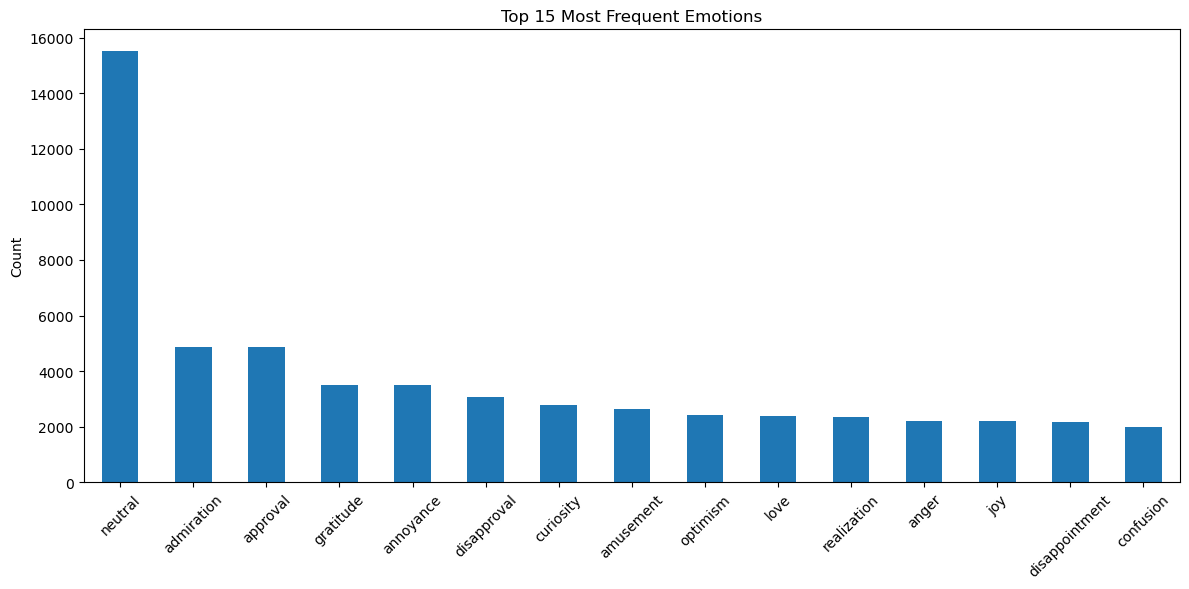

In [20]:
label_counts = df[label_cols].sum().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
label_counts.head(15).plot(kind='bar')
plt.title('Top 15 Most Frequent Emotions')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

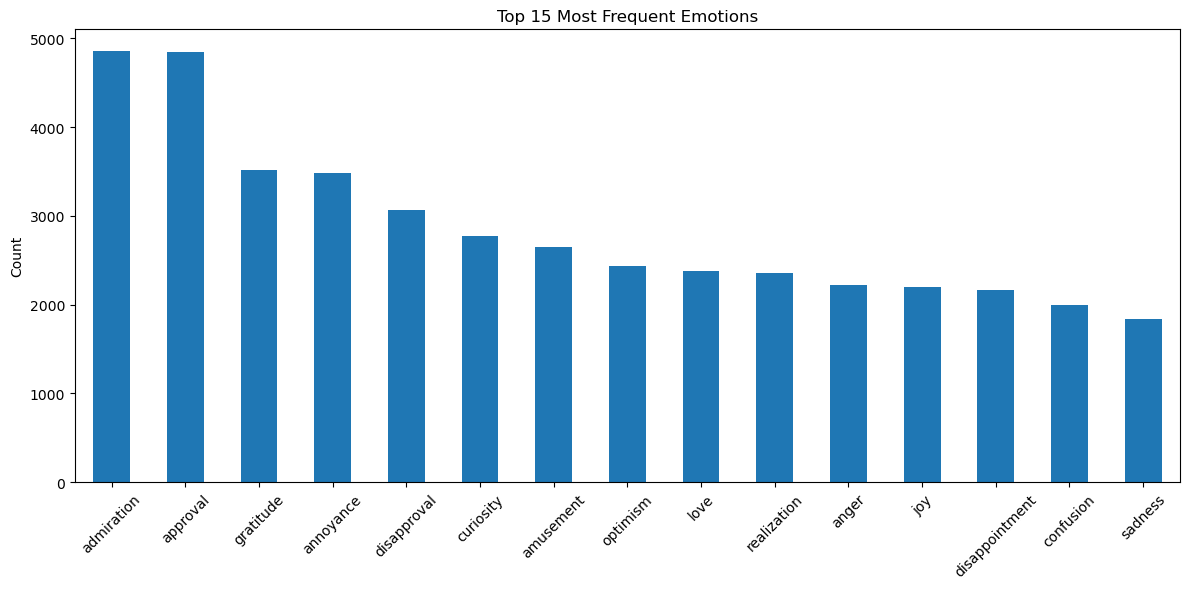

In [27]:
emotion_cols_no_neutral = [col for col in label_cols if col != 'neutral']  # remove neutral
label_counts = df[emotion_cols_no_neutral].sum().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
label_counts.head(15).plot(kind='bar')
plt.title('Top 15 Most Frequent Emotions')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Text Length Distribution (Histogram)

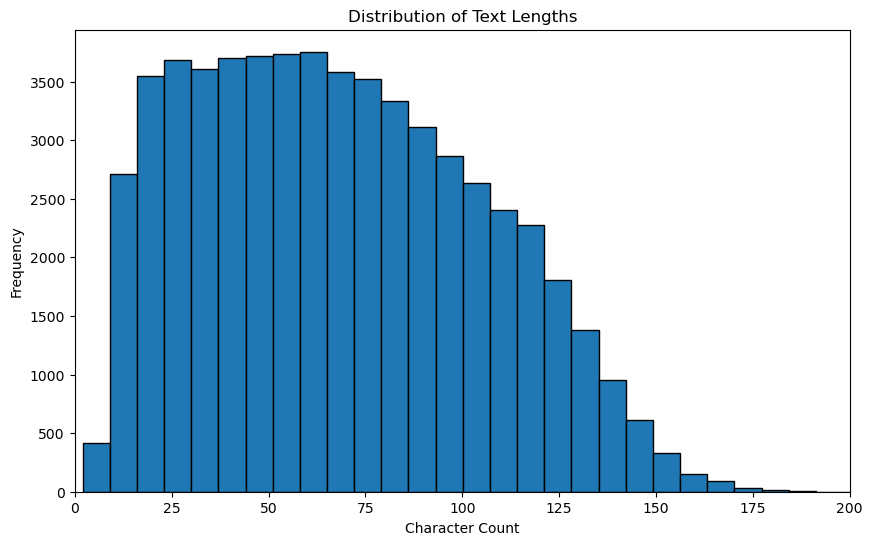

In [21]:
text_len = df["text"].astype(str).str.len()

plt.figure(figsize=(10, 6))
plt.hist(text_len, bins=100, edgecolor='black')
plt.title('Distribution of Text Lengths')
plt.xlabel('Character Count')
plt.ylabel('Frequency')
plt.xlim(0,200)
plt.show()

## Subreddit Emotion Heatmap (Top subreddits)

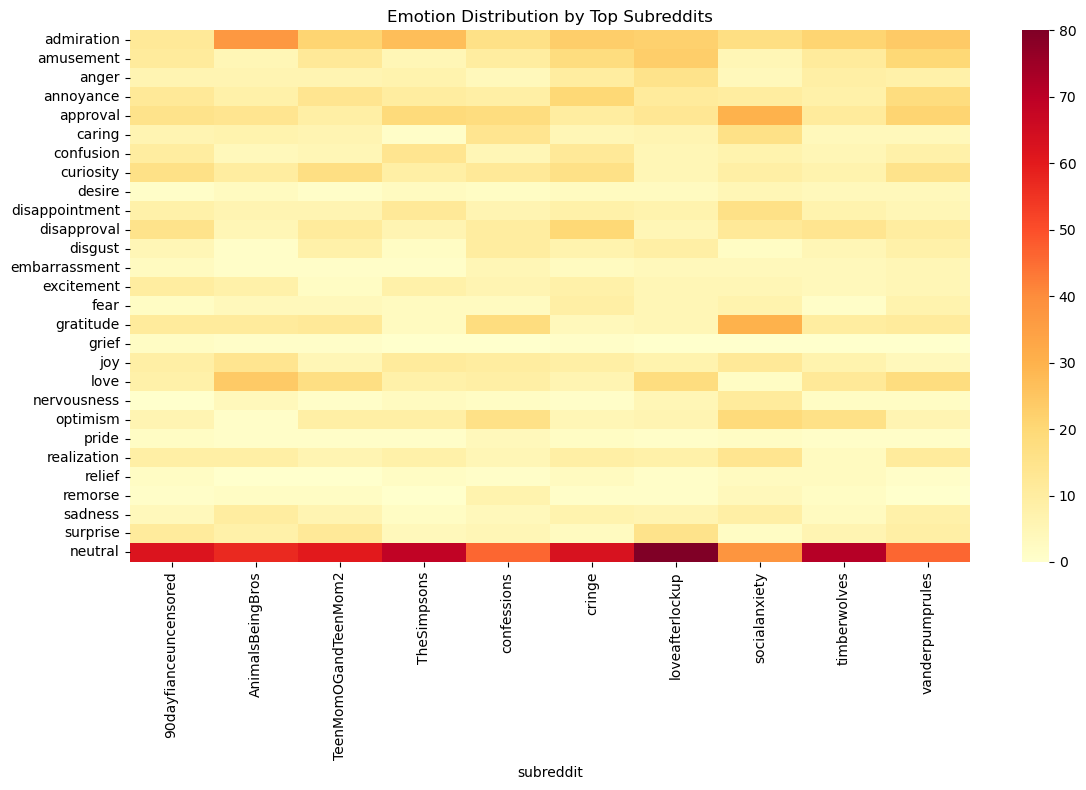

In [22]:
top_subs = df['subreddit'].value_counts().head(10).index
sub_emotion = df[df['subreddit'].isin(top_subs)].groupby('subreddit')[label_cols].sum()
plt.figure(figsize=(12, 8))
sns.heatmap(sub_emotion.T, cmap='YlOrRd', annot=False)
plt.title('Emotion Distribution by Top Subreddits')
plt.tight_layout()
plt.show()

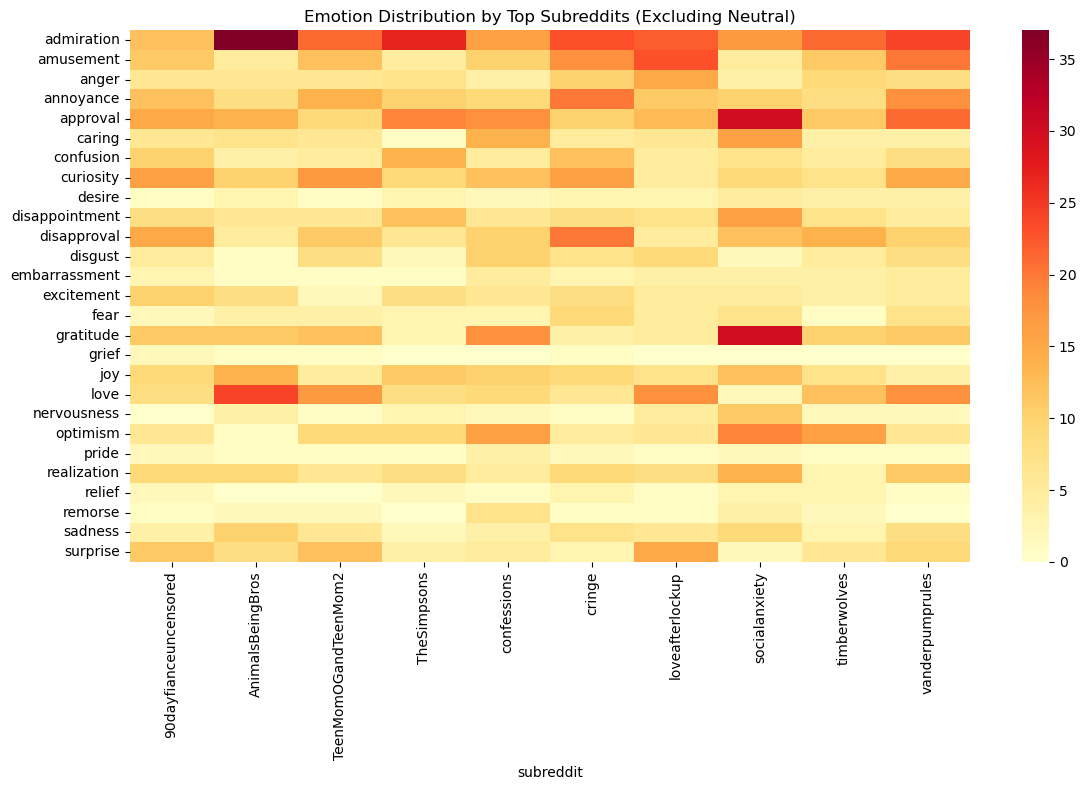

In [26]:
top_subs = df['subreddit'].value_counts().head(10).index
emotion_cols_no_neutral = [col for col in label_cols if col != 'neutral']  # remove neutral
sub_emotion = df[df['subreddit'].isin(top_subs)].groupby('subreddit')[emotion_cols_no_neutral].sum()

plt.figure(figsize=(12, 8))
sns.heatmap(sub_emotion.T, cmap='YlOrRd', annot=False)
plt.title('Emotion Distribution by Top Subreddits (Excluding Neutral)')
plt.tight_layout()
plt.show()


## Multi-label Patterns (Labels per text)

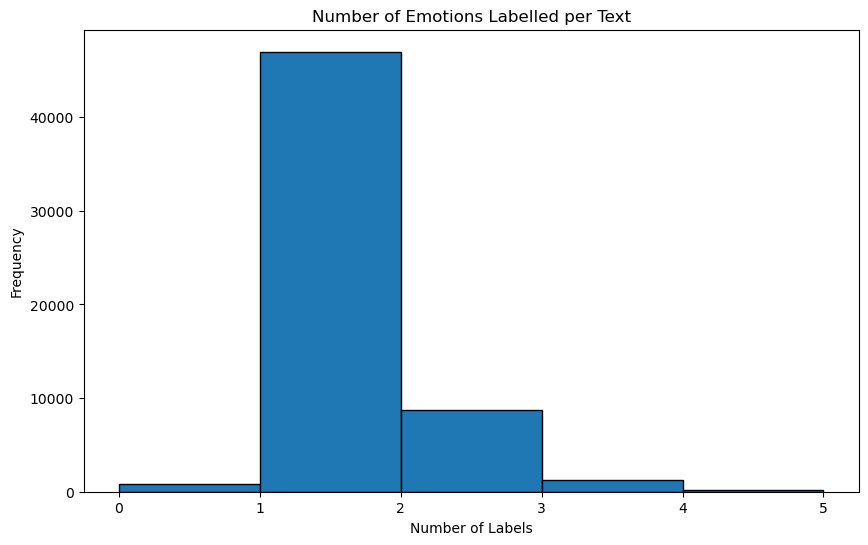

In [25]:
labels_per_row = df[label_cols].sum(axis=1)
plt.figure(figsize=(10, 6))
plt.hist(labels_per_row, bins=range(0, 6), edgecolor='black')
plt.title('Number of Emotions Labelled per Text')
plt.xlabel('Number of Labels')
plt.ylabel('Frequency')
plt.show()